# F_basic_ephys.ipynb

## Purpose
Characterizes electrophysiological unit properties for opto-tagged and untagged neurons. Generates quality-control metric distributions and the go-cue excitation vs. baseline correlation scatter plot.

## Prerequisites
- `basic_ephys.pkl` — basic ephys metrics per unit (`manuscript_fig_prep_dir/basic_ephys/`)
- `acf_fit_parameters_with_pcs.csv` — ACG fit parameters with PCs (`manuscript_fig_prep_dir/acg/`)
- `acf_fit_parameters_and_components.pkl` — ACG fit parameters and components (`manuscript_fig_prep_dir/acg/`)
- `combined_unit_tbl.pkl` — quality-controlled unit table (`manuscript_fig_prep_dir/combined_unit_tbl/`)
- `combined_antidromic_results.pkl` — antidromic classification results (`manuscript_fig_prep_dir/antidromic_analysis/PrL_S1/`)
- `basic_ephys_all.json` — QC criteria (`code/beh_ephys_analysis/session_combine/metrics/`)
- `model_combined_beh_all.csv` — behavioral regression model results per unit (`manuscript_fig_prep_dir/outcome_regressions/`)
- `response_ratio_beh_all_go_cue.csv` — go-cue response ratio per unit (`manuscript_fig_prep_dir/response_regression/`)
- `combined_features.csv` — waveform features (`manuscript_fig_prep_dir/waveforms_np/`)

## Figure Panels
- **Figure4h**: Go-cue excitation versus go-baseline correlation (scatter)
- **FigureE10e**: Single-unit quality metrics for identified and unidentified neurons (scatter + marginal distributions)
- **FigureE10f_topleft**: ISI violation ratio for identified and unidentified neurons (histogram)
- **FigureE10f_topright**: Waveform peak for identified and unidentified neurons (histogram)
- **FigureE10f_bottomleft**: Euclidean distance between waveforms of spontaneous and evoked spikes (histogram)
- **FigureE10f_bottomright**: Correlation between waveforms of spontaneous and evoked spikes (histogram)

## Imports and Path Setup

Import all required libraries and resolve the `beh_ephys_analysis` root so that `utils` sub-modules are importable regardless of execution environment.

In [1]:
import os

# Resolve code/beh_ephys_analysis (the folder containing `utils`) relative to this
# file's location, so imports work no matter where the repo is checked out.
import pathlib
import sys

# Resolve code/beh_ephys_analysis (the folder containing `utils`) relative to this
# file's location, so imports work no matter where the repo is checked out.
try:
    _here = pathlib.Path(__file__).resolve().parent          # script mode
except NameError:
    try:
        _here = pathlib.Path(__vsc_ipynb_file__).resolve().parent  # VS Code notebook
    except NameError:
        _here = pathlib.Path(os.getcwd())                    # other Jupyter fallback

_beh_ephys_root = str((_here / '../..').resolve())
if _beh_ephys_root not in sys.path:
    sys.path.insert(0, _beh_ephys_root)
import json
import pickle
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import pearsonr
from utils.beh_functions import (
    parseSessionID,
)
from utils.capsule_migration import capsule_directories
from utils.combine_tools import (
    apply_qc,
    to_str_intlike,
)
from utils.ephys_functions import *
from scipy.stats import rankdata, zscore
warnings.filterwarnings('ignore')
capsule_dirs = capsule_directories()

%matplotlib inline
from utils.capsule_migration import CAPSULE_ROOT
from utils.panel_utils import columns_to_df, save_panel_csv, save_panels


## Data Loading

Load basic ephys metrics (`basic_ephys.pkl`), ACG fit parameters, the combined unit table with opto-tagging and antidromic stimulation results, and apply the `basic_ephys_all` QC criteria JSON to classify units.

In [2]:
# load basic ephys
target_folder = f'{capsule_dirs["manuscript_fig_dir"]}/F_basic_ephys'
if not os.path.exists(target_folder):
    os.makedirs(target_folder)
be_folder = os.path.join(capsule_dirs["manuscript_fig_prep_dir"], 'basic_ephys')
be_file = os.path.join(be_folder, f'basic_ephys.pkl')
with open(be_file, 'rb') as f:
    basic_ephys_df = pickle.load(f)
filter = basic_ephys_df['be_filter'].values
filter = np.array(filter, dtype=bool)
basic_ephys_df['be_filter'] = filter
basic_ephys_df.rename(columns={'unit': 'unit_id'}, inplace=True)
basic_ephys_df['unit_id'] = basic_ephys_df['unit_id'].apply(to_str_intlike)

In [3]:
# load parameters for acg
fit_params_file = os.path.join(capsule_dirs["manuscript_fig_prep_dir"], 'acg', 'acf_fit_parameters_with_pcs.csv')
fit_params_df = pd.read_csv(fit_params_file)
fit_params_mat_file = os.path.join(capsule_dirs["manuscript_fig_prep_dir"], 'acg', 'acf_fit_parameters_and_components.pkl')
with open(fit_params_mat_file, 'rb') as f:
    fit_data = pickle.load(f)
C1_mat = fit_data['C1_mat']
C2_mat = fit_data['C2_mat']
C3_mat = fit_data['C3_mat']
auto_corr = fit_data['acg_mat']
# add_auto_corr to df
fit_params_df['C1'] = C1_mat.tolist()  # convert numpy array to list for storage in DataFrame
fit_params_df['C2'] = C2_mat.tolist()  # convert numpy array to list for storage in DataFrame
fit_params_df['C3'] = C3_mat.tolist()  # convert numpy array to list for storage in DataFrame
fit_params_df['auto_corr'] = auto_corr.tolist()  # convert numpy array to list for storage in DataFrame

In [4]:
with open(os.path.join(capsule_dirs["manuscript_fig_prep_dir"], 'combined_unit_tbl', 'combined_unit_tbl.pkl'), 'rb') as f:
    combined_tagged_units = pickle.load(f)
combined_tagged_units.rename(columns={'unit': 'unit_id'}, inplace=True)
# exlcude units from excluded sessions
combined_tagged_units['unit_id'] = combined_tagged_units['unit_id'].apply(to_str_intlike)
# antidromic data
# version = 'PrL_S1'
# antidromic_file = f'{capsule_dirs["manuscript_fig_prep_dir"]}/antidromic_analysis/{version}/combined_antidromic_results.pkl'
# with open(antidromic_file, 'rb') as f:
#     antidromic_df = pickle.load(f)

# antidromic_df.rename(columns={'unit': 'unit_id'}, inplace=True)
# antidromic_df['unit_id'] = antidromic_df['unit_id'].apply(to_str_intlike)
# antidromic_df = antidromic_df[['unit_id', 'session', 'p_auto_inhi', 't_auto_inhi',
#        'p_collision', 't_collision', 'p_antidromic', 't_antidromic', 'tier_1',
#        'tier_2', 'tier_1_long', 'tier_2_long']].copy()
# combined_tagged_units = combined_tagged_units.merge(antidromic_df, on=['session', 'unit_id'], how='left')
# combined_tagged_units['tier_1'] = combined_tagged_units['tier_1'].fillna(False)
# combined_tagged_units['tier_2'] = combined_tagged_units['tier_2'].fillna(False)
# combined_tagged_units['tier_1_long'] = combined_tagged_units['tier_1_long'].fillna(False)
# combined_tagged_units['tier_2_long'] = combined_tagged_units['tier_2_long'].fillna(False)


## Quality Control: Apply Filters and Visualize Metrics

Apply the `basic_ephys_all` QC constraints to produce a filtered set of high-quality opto-tagged units, and save a summary figure of the unit quality metrics distribution.

Applying bounds for isi_violations: [0, 0.1]
 - isi_violations: 6539 -> 2898 units passed
Applying items for in_LC: [True]
 - in_LC: 2898 -> 816 units passed
Applying items for qc_pass: [True]
 - qc_pass: 816 -> 575 units passed
Applying bounds for peak: [-1000, 500]
 - peak: 575 -> 575 units passed
Applying bounds for sd: [0, 0.5]
 - sd: 575 -> 377 units passed
Applying conditional bounds for y_loc
 - y_loc: 377 -> 376 units passed
Applying opto conditions: ['p_max', 'eu', 'corr', 'tag_loc', 'lat_max_p', 'p_mean', 'sig_counts']
Number of opto rows after filtering: 94
Number of non-opto rows after filtering: 376


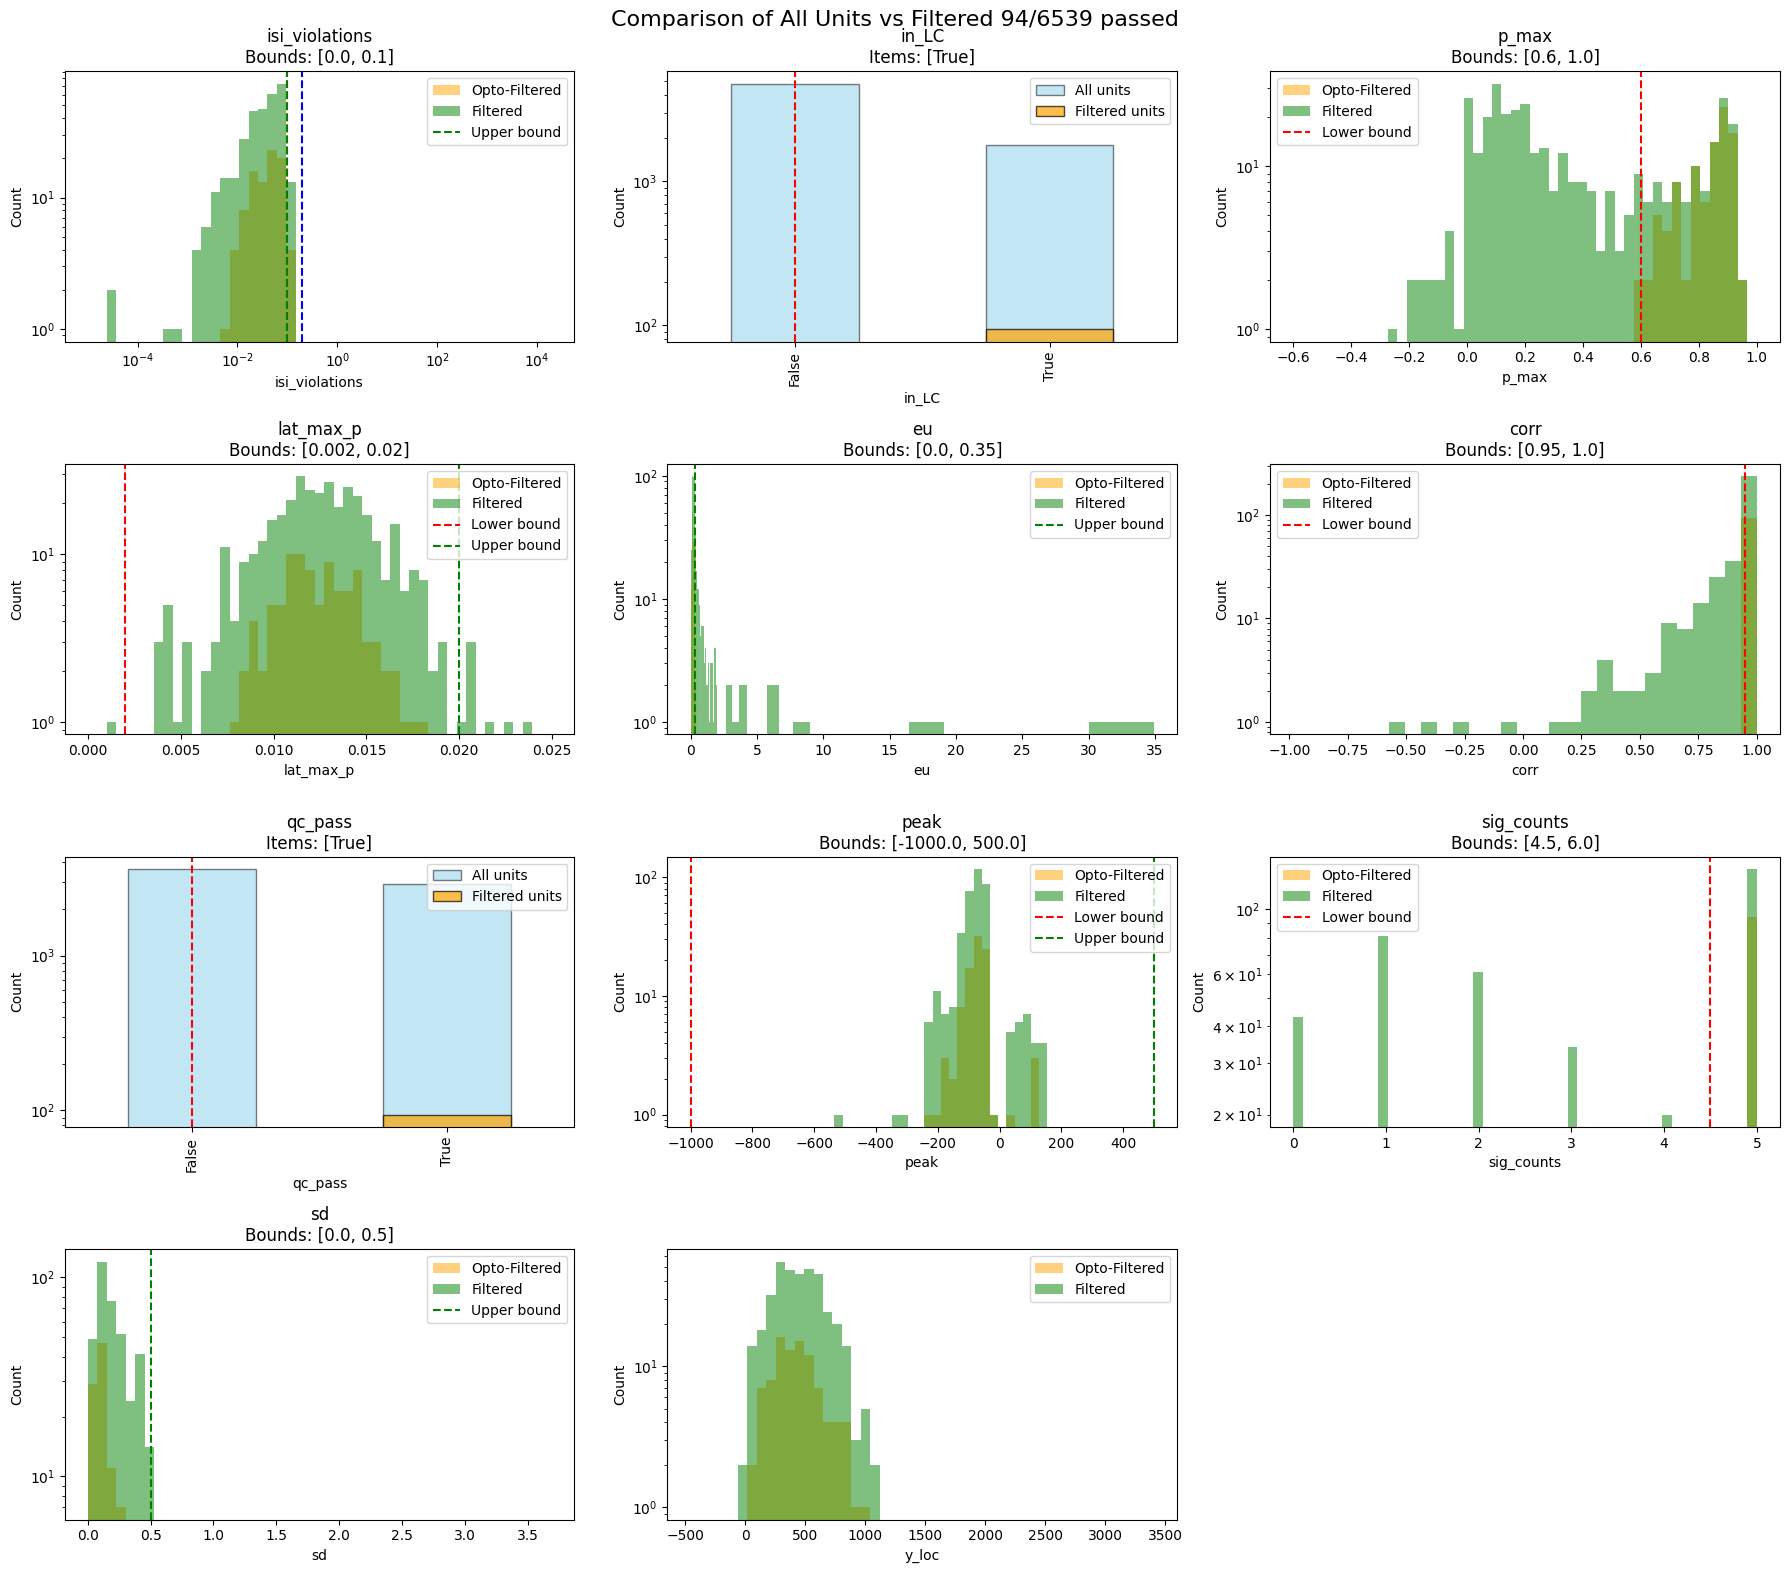

In [5]:
density = False
criteria_name = 'basic_ephys_all_LC'
with open(os.path.join(CAPSULE_ROOT + '/code/beh_ephys_analysis/session_combine/metrics', f'{criteria_name}.json'), 'r') as f:
    constraints = json.load(f)
constraints['sd'] = {'bounds': [0, 0.5]}
combined_tagged_units_filtered, combined_tagged_units, fig, axes = apply_qc(combined_tagged_units, constraints, density=density, plot_all=False, plot_half=True)
combined_tagged_units_filtered = combined_tagged_units[combined_tagged_units['selected_qc_only']].copy()
combined_tagged_units.rename(columns={'unit': 'unit_id'}, inplace=True)
combined_tagged_units['unit_id'] = combined_tagged_units['unit_id'].apply(to_str_intlike)
# Broad boundary marking all possible NE neurons
NE_maybe = {'p_max': [0.3, 1.1],
            'sig_counts': [4.5, 5.5]}
combined_tagged_units_filtered['opto_maybe'] = (
    combined_tagged_units_filtered['p_max'].between(*NE_maybe['p_max']) &
    combined_tagged_units_filtered['sig_counts'].between(*NE_maybe['sig_counts'])
)
combined_tagged_units_filtered.rename(columns={'unit': 'unit_id'}, inplace=True)
combined_tagged_units_filtered['unit_id'] = combined_tagged_units_filtered['unit_id'].apply(to_str_intlike)
fig.savefig(fname=os.path.join(target_folder, f'unit_quality_metrics_summary_density_{density}.pdf'))
fig.savefig(fname=os.path.join(target_folder, f'unit_quality_metrics_summary_density_{density}.svg'))

In [6]:
combined_tagged_units.groupby('selected_qc_only').count()

,session,unit_id,qc_pass,opto_tagged,in_df,trial_count,p_max,p_mean,sig_counts,lat_max_p,...,all_sig_counts,x_ccf,y_ccf,z_ccf,sd,rec_len,count_max,selected_opto_only,selected,selected_no_opto
selected_qc_only,,,,,,,,,,,,,,,,,,,,,
False,6163,6163,6163,6163,6163,6163,6163,6163,2533,5514,...,6163,5673,5673,5673,6162,6163,118,6163,6163,6163
True,376,376,376,376,376,376,376,376,376,371,...,376,342,342,342,376,376,94,376,376,376


In [7]:
combined_tagged_units_filtered.groupby('selected').count()


,session,unit_id,qc_pass,opto_tagged,in_df,trial_count,p_max,p_mean,sig_counts,lat_max_p,...,x_ccf,y_ccf,z_ccf,sd,rec_len,selected_qc_only,count_max,selected_opto_only,selected_no_opto,opto_maybe
selected,,,,,,,,,,,,,,,,,,,,,
False,282,282,282,282,282,282,282,282,282,277,...,251,251,251,282,282,282,0,282,282,282
True,94,94,94,94,94,94,94,94,94,94,...,91,91,91,94,94,94,94,94,94,94


## Quality Metric Histograms (Identified vs. Unidentified Neurons)

Plot histograms comparing all QC-passing units against opto-tagged units for four metrics: Euclidean waveform distance, waveform correlation, ISI violation rate, and waveform peak amplitude.

In [8]:
combined_tagged_units_good = combined_tagged_units[combined_tagged_units['selected_qc_only']].copy().reset_index(drop=True)

In [9]:
combined_tagged_units_good['p_mean_max'] = combined_tagged_units_good['all_p_mean'].apply(
    lambda x: np.max(x) if len(x) > 0 else np.nan
)

combined_tagged_units_good['p_mean_mean'] = combined_tagged_units_good['all_p_mean'].apply(
    lambda x: np.mean(x) if len(x) > 0 else np.nan
)

['/root/capsule/scratch/result/manuscript/figures/F_basic_ephys/FigureE10f_bottomleft_euclidean_distance_histogram.csv']

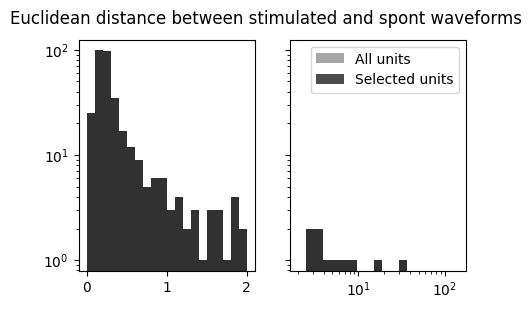

In [10]:
# plot euclidean distance histogram, with linear bins from 0 to boundary, and log bins larger than that
col = 'eu'
boundary = 2
tag_color = 'k'
nontag_color = 'gray'
edges_small = np.arange(0, boundary+0.1, 0.1)
edges_large = np.logspace(np.log10(boundary), np.log10(combined_tagged_units[col].max()), 20)
fig, axes = plt.subplots(1, 2, figsize=(5, 3), sharey=True)
ax = axes[0]
ax.hist(combined_tagged_units_good[col], bins=edges_small, color=nontag_color, alpha=0.7)
ax.hist(combined_tagged_units_filtered[col], bins=edges_small, color=tag_color, alpha=0.7)
ax.set_yscale('log')
ax = axes[1]
ax.hist(combined_tagged_units_good[col], bins=edges_large, color=nontag_color, alpha=0.7)
ax.hist(combined_tagged_units_filtered[col], bins=edges_large, color=tag_color, alpha=0.7)
ax.set_xscale('log')
ax.set_yscale('log')
plt.suptitle('Euclidean distance between stimulated and spont waveforms')
plt.legend(['All units', 'Selected units'])
save_panels(fig, target_folder, f'euclidean_distance_histogram', ['FigureE10f_bottomleft'], exts=('pdf',))
# ---- panel CSV (rule 8 histogram: all vs selected units) ----
save_panel_csv(columns_to_df(**{f'{col}_all_good': combined_tagged_units_good[col].dropna().values, f'{col}_opto_tagged': combined_tagged_units_filtered[col].dropna().values}), target_folder, f'euclidean_distance_histogram', ['FigureE10f_bottomleft'])
###FigureE10f_bottomleft### dont't separate panels for histogram data save. Just one all good unit, one opto-tagged unit 

['/root/capsule/scratch/result/manuscript/figures/F_basic_ephys/FigureE10f_bottomright_correlation_histogram.csv']

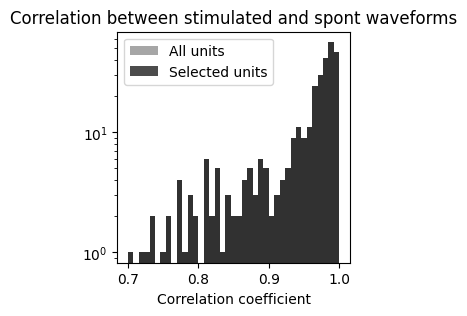

In [11]:
# plot euclidean distance histogram, with linear bins from 0 to boundary, and log bins larger than that
col = 'corr'
fig, ax = plt.subplots(1, 1, figsize=(3, 3))
edges = np.linspace(0.7, 1, 40)
ax.hist(combined_tagged_units_good[col], bins=edges, color=nontag_color, alpha=0.7);
ax.hist(combined_tagged_units_filtered[col], bins=edges, color=tag_color, alpha=0.7);
ax.set_yscale('log')
plt.title('Correlation between stimulated and spont waveforms')
ax.set_xlabel('Correlation coefficient')
plt.legend(['All units', 'Selected units'])
save_panels(fig, target_folder, f'correlation_histogram', ['FigureE10f_bottomright'], exts=('pdf',))
# ---- panel CSV (rule 8 histogram: all vs selected units) ----
save_panel_csv(columns_to_df(**{f'{col}_all_good': combined_tagged_units_good[col].dropna().values, f'{col}_opto_tagged': combined_tagged_units_filtered[col].dropna().values}), target_folder, f'correlation_histogram', ['FigureE10f_bottomright'])
###FigureE10f_bottomright###

['/root/capsule/scratch/result/manuscript/figures/F_basic_ephys/FigureE10f_topleft_ISI_histogram.csv']

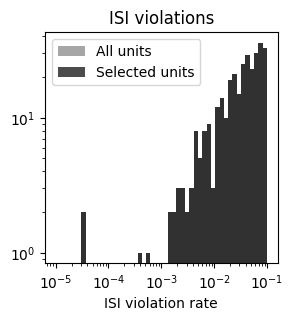

In [12]:
# plot ISI violation
col = 'isi_violations'
fig, ax = plt.subplots(1, 1, figsize=(3, 3))
edges = np.logspace(np.log10(1e-5), np.log10(np.nanmax(combined_tagged_units_good[col])), 50)
ax.hist(combined_tagged_units_good[col], bins=edges, color=nontag_color, alpha=0.7);
ax.hist(combined_tagged_units_filtered[col], bins=edges, color=tag_color, alpha=0.7);
ax.set_yscale('log')
ax.set_xscale('log')
plt.title('ISI violations')
ax.set_xlabel('ISI violation rate')
plt.legend(['All units', 'Selected units'])
save_panels(fig, target_folder, f'ISI_histogram', ['FigureE10f_topleft'], exts=('pdf',))

# ---- panel CSV (rule 8 histogram: all vs selected units) ----
save_panel_csv(columns_to_df(**{f'{col}_all_good': combined_tagged_units_good[col].dropna().values, f'{col}_opto_tagged': combined_tagged_units_filtered[col].dropna().values}), target_folder, f'ISI_histogram', ['FigureE10f_topleft'])
###FigureE10f_topleft### 

['/root/capsule/scratch/result/manuscript/figures/F_basic_ephys/FigureE10f_topright_peak_histogram.csv']

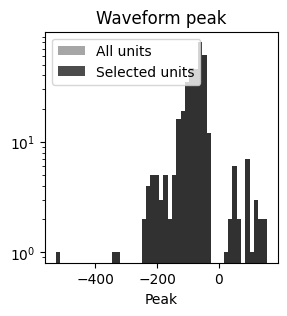

In [13]:
# plot waveform peak
col = 'peak'
fig, ax = plt.subplots(1, 1, figsize=(3, 3))
edges = np.linspace(np.nanmin(combined_tagged_units_good[col]), np.nanmax(combined_tagged_units_good[col]), 50)
ax.hist(combined_tagged_units_good[col], bins=edges, color=nontag_color, alpha=0.7);
ax.hist(combined_tagged_units_filtered[col], bins=edges, color=tag_color, alpha=0.7);
ax.set_yscale('log')
plt.title('Waveform peak')
ax.set_xlabel('Peak')
plt.legend(['All units', 'Selected units'])
save_panels(fig, target_folder, f'peak_histogram', ['FigureE10f_topright'], exts=('pdf',))
# ---- panel CSV (rule 8 histogram: all vs selected units) ----
save_panel_csv(columns_to_df(**{f'{col}_all_good': combined_tagged_units_good[col].dropna().values, f'{col}_opto_tagged': combined_tagged_units_filtered[col].dropna().values}), target_folder, f'peak_histogram', ['FigureE10f_topright'])
###FigureE10f_topright### 

## Load Behavioral Model Variables and Merge Feature Tables

Load outcome regression coefficients, response ratio table, and waveform features, then merge everything into a single `features_combined` DataFrame keyed on session and unit ID.

In [14]:
# load and add model variables
beh_folder = os.path.join(capsule_dirs["manuscript_fig_prep_dir"], 'outcome_regressions')
model_combined = pd.read_csv(os.path.join(beh_folder, 'model_combined_beh_all_LC.csv'), index_col=0)
model_combined['theta'] = model_combined['theta'] - 0.5
model_combined['unit_id'] = model_combined['unit_id'].apply(to_str_intlike)

versions = ['e', 'l', 'com']
for version in versions:
    all_vec = np.column_stack((
        model_combined[f'coef_outcome_{version}_mc'],
        model_combined[f'coef_Qchosen_{version}_ori']
    ))
    theta, rho = np.arctan2(all_vec[:, 1], all_vec[:, 0]), np.hypot(all_vec[:, 1], all_vec[:, 0])
    bound_1, bound_2, bound_3 = -(1 / 4) * np.pi, np.pi, -np.pi
    theta_scaled_dis = np.zeros_like(theta)
    for ind, angle_curr in enumerate(theta):
        if bound_1 < angle_curr <= bound_2:
            theta_scaled_dis[ind] = (angle_curr - bound_1) / (bound_2 - bound_1)
        else:
            theta_scaled_dis[ind] = (bound_1 - angle_curr) / (bound_1 - bound_3)
    theta_scaled_dis_all = 1 - theta_scaled_dis - 0.5
    model_combined[f'theta_{version}'] = theta_scaled_dis_all

# derived features
model_combined['coef_outcome|(|coef_outcome| + |coef_Q|)'] = (
    model_combined['coef_outcome_com_mc'] /
    (np.abs(model_combined['coef_outcome_com_mc']) + np.abs(model_combined['coef_Qchosen_com_mc']))
)
model_combined['outcome_ipsi'] = (
    model_combined['coef_outcome_com_mc'] + model_combined['coef_outcome:ipsi_com_mc']
)
model_combined['outcome_contra'] = (
    model_combined['coef_outcome_com_mc'] - model_combined['coef_outcome:ipsi_com_mc']
)

response_tbl = pd.read_csv(os.path.join(capsule_dirs["manuscript_fig_prep_dir"], 'response_regression', 'response_ratio_beh_all_LC_go_cue.csv'))
response_tbl['unit_id'] = response_tbl['unit'].apply(to_str_intlike)


In [15]:
features_combined = basic_ephys_df.merge(combined_tagged_units_filtered[['session', 'unit_id', 'sex', 'x_ccf', 'y_ccf', 'z_ccf', 'selected']], on=['session', 'unit_id'], how='inner')
features_combined = features_combined.rename(columns={'selected': 'opto'})
features_combined = features_combined.merge(model_combined, on=['session', 'unit_id'], how='left')
features_combined = features_combined.merge(response_tbl, on=['session', 'unit_id'], how='left')

In [16]:
# # load waveforms and merge
# waveform_file = os.path.join(capsule_dirs["manuscript_fig_prep_dir"], 'waveforms_np', 'combined_features.csv')
# wf_combined_features = pd.read_csv(waveform_file)
# wf_combined_features.rename(columns={'unit': 'unit_id'}, inplace=True)
# wf_combined_features['unit_id'] = wf_combined_features['unit_id'].apply(to_str_intlike)
# features_combined = features_combined.merge(wf_combined_features, on=['session', 'unit_id'], how='left')
fit_params_df['unit_id'] = fit_params_df['unit_id'].apply(to_str_intlike)
features_combined = features_combined.merge(fit_params_df, on=['session', 'unit_id'], how='left')

In [17]:
# Merge p_max and sig_counts from combined_tagged_units so we can apply opto criteria
_opto_cols = combined_tagged_units_filtered[['session', 'unit_id', 'p_max', 'sig_counts', 'selected', 'opto_maybe']].copy()
features_combined = features_combined.merge(_opto_cols, on=['session', 'unit_id'], how='left')

# Broad boundary marking all possible NE neurons
NE_maybe = {'p_max': [0.3, 1.1],
            'sig_counts': [4.5, 5.5]}
features_combined['opto_maybe'] = (
    features_combined['p_max'].between(*NE_maybe['p_max']) &
    features_combined['sig_counts'].between(*NE_maybe['sig_counts'])
)

In [18]:
features_combined.groupby(['opto_maybe']).count()

,session,unit_id,bl_mean,response_rate,response_fr,response_bias,response_diff,bl_diff,outcome_diff,outcome_diff_abs,...,PC3,PC4,PC5,C1,C2,C3,auto_corr,p_max,sig_counts,selected
opto_maybe,,,,,,,,,,,,,,,,,,,,,
False,173,173,173,173,173,172,155,156,173,173,...,68,68,68,103,103,103,103,173,173,173
True,124,124,124,122,122,122,113,113,122,122,...,104,104,104,107,107,107,107,124,124,124


## Basic Ephys Features in CCF Space (Non-Tagged Neurons)

For units where `opto_maybe` is False, map each basic ephys feature onto CCF anatomical coordinates across three projection planes (sagittal, horizontal, coronal), following the approach in `F_waveform_space.ipynb`.

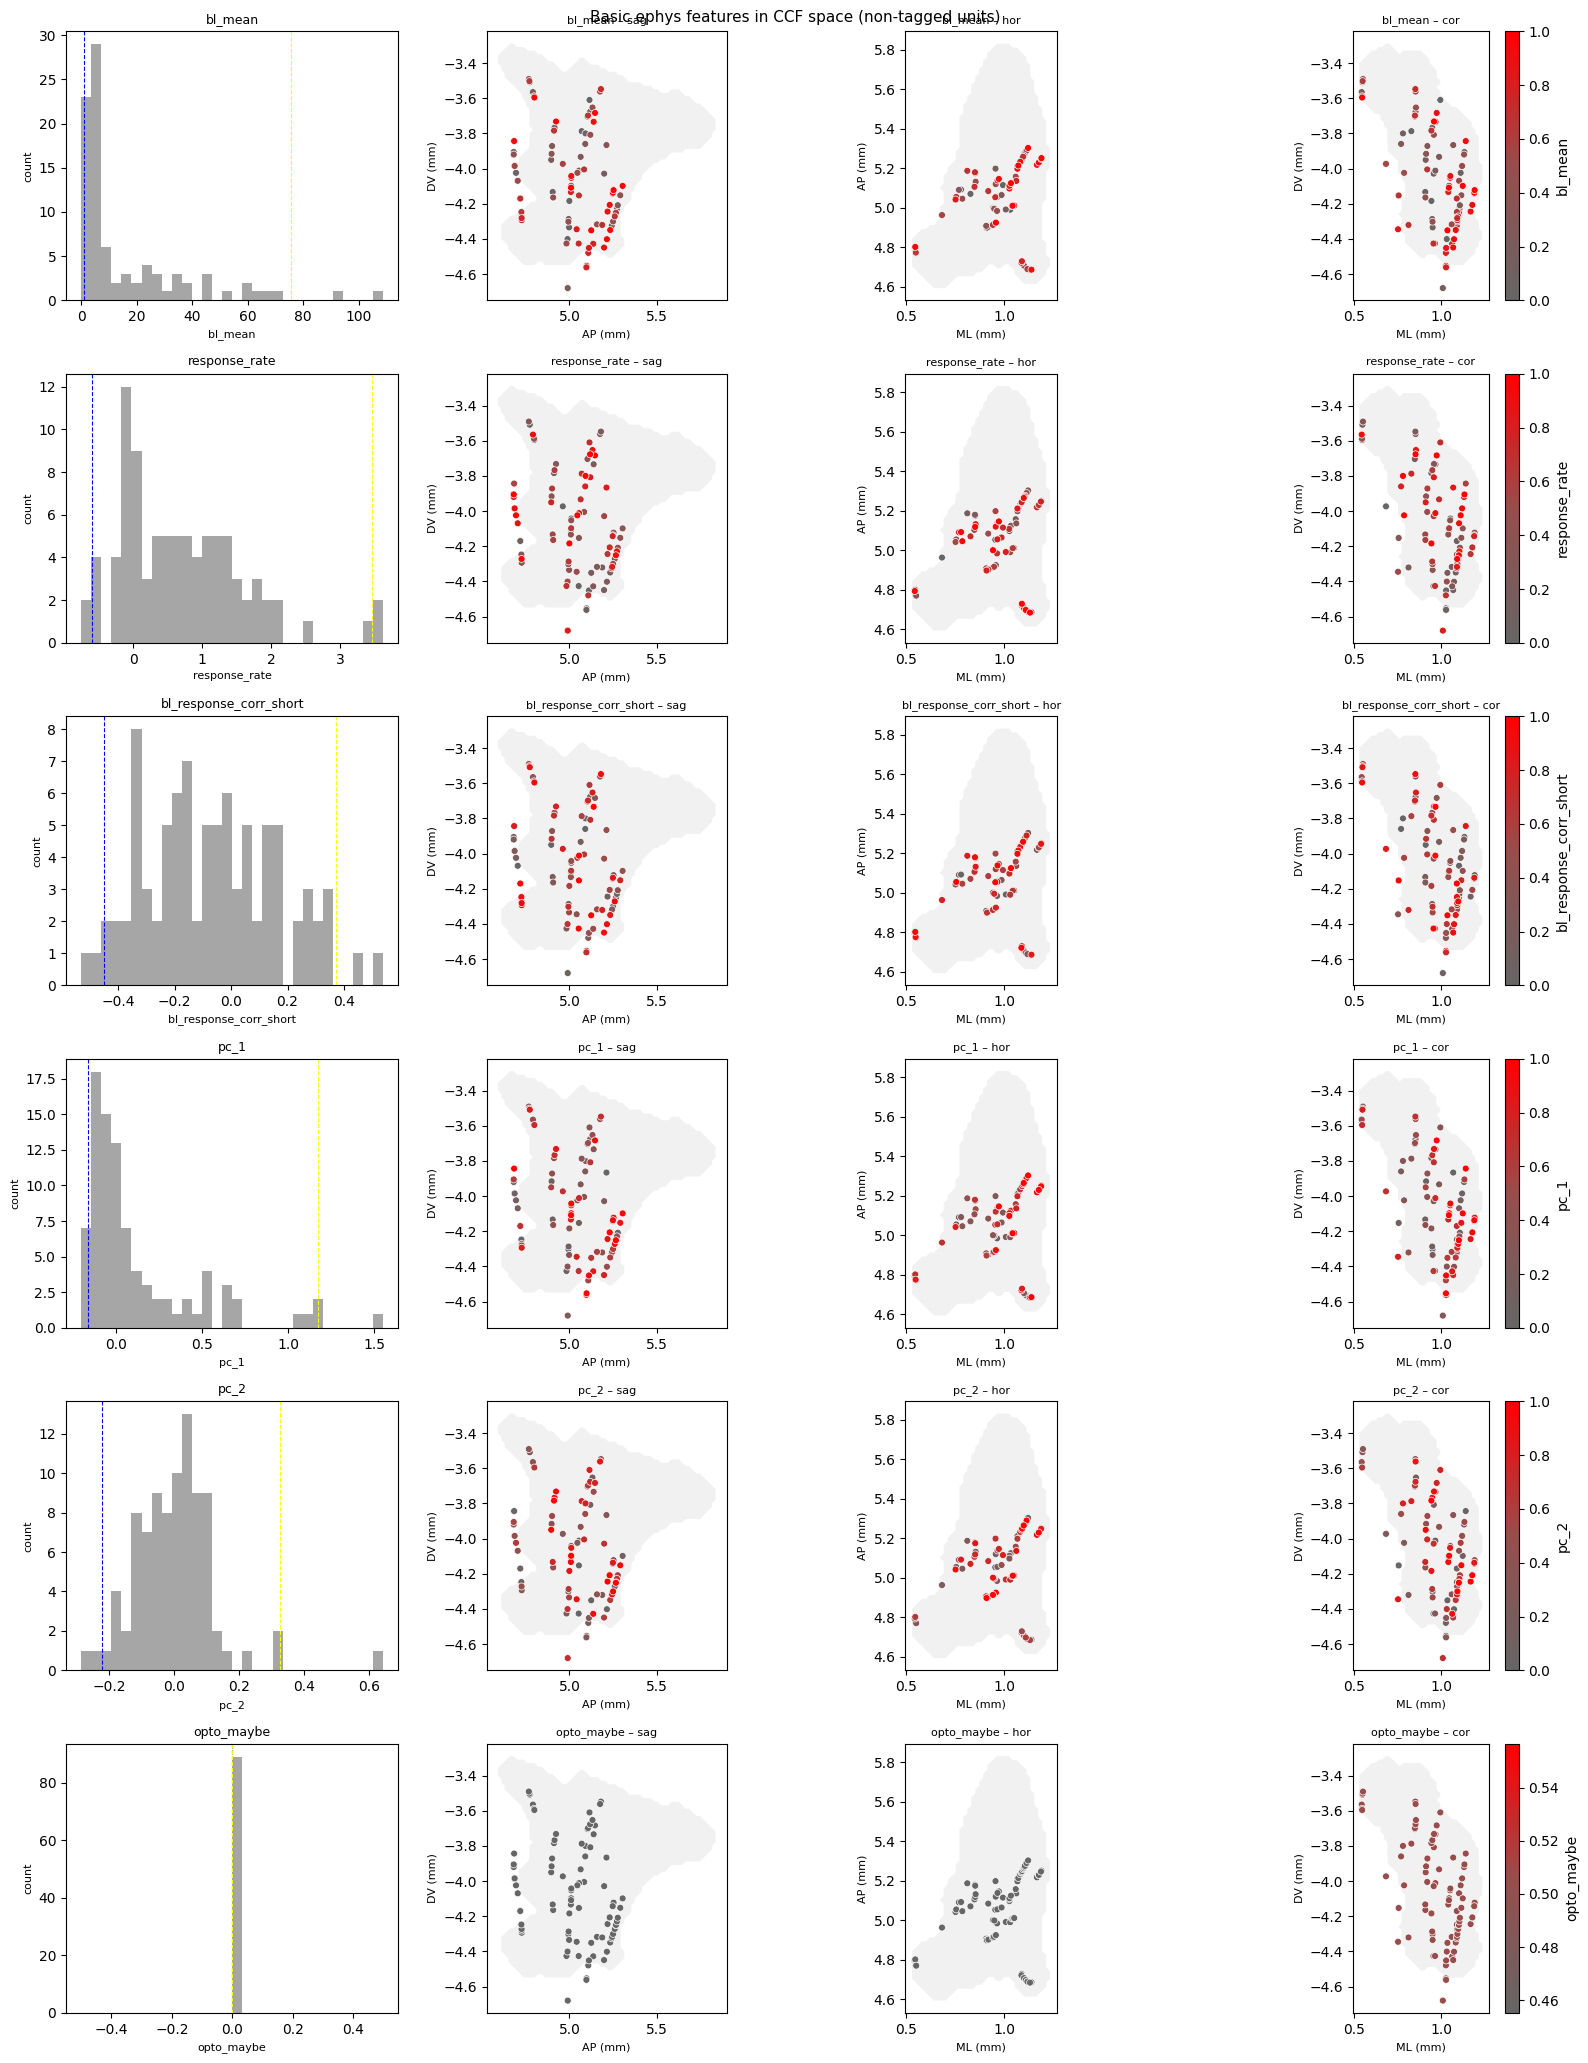

In [19]:
from matplotlib.colors import LinearSegmentedColormap, Normalize
from trimesh import load_mesh
from utils.ccf_utils import project_to_plane

# ── columns to visualise ──────────────────────────────────────────────────
plot_features = [
    'bl_mean',               # baseline firing rate
    'response_rate',         # normalised go-cue response (fr ratio)
    'bl_response_corr_short',# baseline–response correlation
    'pc_1',
    'pc_2',
    'opto_maybe'
]

# ── filter: non-tagged, passing basic QC, valid CCF ───────────────────────
space_mask = (
    (~features_combined['opto_maybe']) &
    features_combined['be_filter'] &
    features_combined[['x_ccf', 'y_ccf', 'z_ccf']].notna().all(axis=1)
)
df_space = features_combined[space_mask].reset_index(drop=True)

# ── CCF coordinate transform (match F_waveform_space.ipynb) ──────────────
ml, ap, dv = 0, 1, 2
planes = {'sag': [ap, dv], 'hor': [ml, ap], 'cor': [ml, dv]}
bregma_LPS_mm = np.array([-5.74, 5.4, -0.45])

ccfs = df_space[['x_ccf', 'y_ccf', 'z_ccf']].values.copy()
ccfs = ccfs - bregma_LPS_mm
ccfs[:, ml] = np.abs(ccfs[:, ml])  # mirror ML to left

# ── mesh ─────────────────────────────────────────────────────────────────
mesh_file = str(capsule_directories()['data_dir']) + '/LC_percentile_meshes/core_mesh.obj'
mesh = load_mesh(mesh_file)
mesh_vertices = np.array(mesh.vertices) / 1000
mesh_vertices_mm = mesh_vertices.copy()
mesh_vertices_mm[:, 2] = -mesh_vertices_mm[:, 2]
mesh_vertices_mm[:, 0] = -mesh_vertices_mm[:, 0]
mesh_vertices_mm = mesh_vertices_mm - bregma_LPS_mm
mesh_vertices_mm[:, ml] = np.abs(mesh_vertices_mm[:, ml])

mesh_contours = {
    pname: project_to_plane(mesh_vertices_mm, paxes, pitch=0.02, margin=0.5)
    for pname, paxes in planes.items()
}

# ── colormap ─────────────────────────────────────────────────────────────
cmap = LinearSegmentedColormap.from_list(
    'be_cmap', [(0.4, 0.4, 0.4), (0.6, 0.3, 0.3), (1.0, 0.0, 0.0)]
)

# ── spatial plot loop ─────────────────────────────────────────────────────
space_target_folder = os.path.join(capsule_dirs['manuscript_fig_dir'], 'F_basic_ephys_space')
os.makedirs(space_target_folder, exist_ok=True)

n_planes = len(planes)  # 3
fig, axes = plt.subplots(
    len(plot_features), 1 + n_planes,
    figsize=(4 * (1 + n_planes), 3.5 * len(plot_features)),
    squeeze=False,
)

for ind, feature in enumerate(plot_features):
    values = df_space[feature].values.astype(float)
    valid = np.isfinite(values)

    # histogram
    ax = axes[ind, 0]
    ax.hist(values[valid], bins=30, color='gray', alpha=0.7)
    ax.set_title(feature, fontsize=9)
    ax.set_xlabel(feature, fontsize=8)
    ax.set_ylabel('count', fontsize=8)

    # normalise to [0,1] clipped at 2–98th percentile for colour mapping
    lo, hi = np.nanquantile(values, 0.02), np.nanquantile(values, 0.98)
    ax.axvline(lo, color='blue', linestyle='--', linewidth=0.8)
    ax.axvline(hi, color='yellow', linestyle='--', linewidth=0.8)
    # change to rank-based normalisation to avoid outlier effects
    nan_mask = np.isnan(values)
    values[~nan_mask] = rankdata(values[~nan_mask]) / np.sum(~nan_mask)
    hi = 0.98
    lo = 0.02
    color_nl = np.clip(values, lo, hi)
    color_nl = (color_nl - lo) / (hi - lo + 1e-12)
    sort_ind = np.argsort(color_nl)

    # three spatial projections
    for col_idx, (plane_name, plane_axes) in enumerate(planes.items()):
        ax = axes[ind, 1 + col_idx]
        for contour in mesh_contours[plane_name]:
            ax.fill(contour[:, 0], contour[:, 1], color='lightgray', alpha=0.3, linewidth=0)
        sc = ax.scatter(
            ccfs[sort_ind, plane_axes[0]],
            ccfs[sort_ind, plane_axes[1]],
            c=color_nl[sort_ind], cmap=cmap,
            s=25, edgecolor=[1, 1, 1], linewidth=0.5, alpha=1,
        )
        ax.set_aspect('equal')
        ax.set_xlabel(['ML', 'AP', 'DV'][plane_axes[0]] + ' (mm)', fontsize=8)
        ax.set_ylabel(['ML', 'AP', 'DV'][plane_axes[1]] + ' (mm)', fontsize=8)
        ax.set_title(f'{feature} – {plane_name}', fontsize=8)
        if plane_name == 'cor':
            fig.colorbar(sc, ax=ax, fraction=0.05, label=feature)

plt.suptitle('Basic ephys features in CCF space (non-tagged units)', fontsize=11)
plt.tight_layout()
save_panels(fig, space_target_folder, f'basic_ephys_in_space_{criteria_name}', [], exts=('pdf', 'svg'), dpi=150, bbox_inches='tight')

# panel CSV: one scatter file per feature
for feature in plot_features:
    values = df_space[feature].values.astype(float)
    valid = np.isfinite(values) & np.all(np.isfinite(ccfs), axis=1)
    save_panel_csv(
        columns_to_df(**{
            'x_ccf_mm': ccfs[valid, 0], 'y_ccf_mm': ccfs[valid, 1], 'z_ccf_mm': ccfs[valid, 2],
            feature: values[valid],
        }),
        space_target_folder, f'basic_ephys_space_{feature}_{criteria_name}', [],
    )

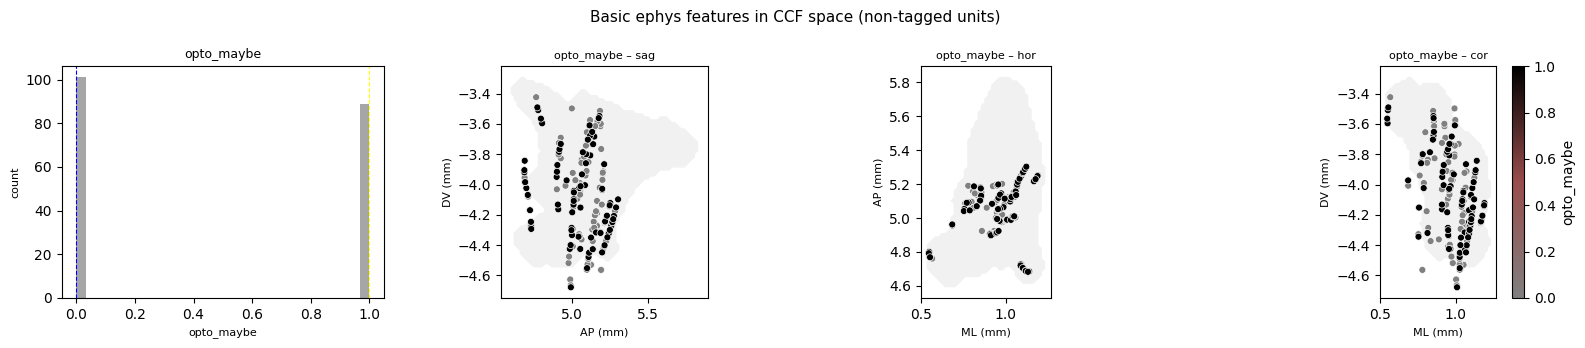

In [20]:
from matplotlib.colors import LinearSegmentedColormap, Normalize
from trimesh import load_mesh
from utils.ccf_utils import project_to_plane

# ── columns to visualise ──────────────────────────────────────────────────
plot_features = [
    'opto_maybe'
]

# ── filter: non-tagged, passing basic QC, valid CCF ───────────────────────
space_mask = (
    features_combined['be_filter'] &
    features_combined[['x_ccf', 'y_ccf', 'z_ccf']].notna().all(axis=1)
)
df_space = features_combined[space_mask].reset_index(drop=True)

# ── CCF coordinate transform (match F_waveform_space.ipynb) ──────────────
ml, ap, dv = 0, 1, 2
planes = {'sag': [ap, dv], 'hor': [ml, ap], 'cor': [ml, dv]}
bregma_LPS_mm = np.array([-5.74, 5.4, -0.45])

ccfs = df_space[['x_ccf', 'y_ccf', 'z_ccf']].values.copy()
ccfs = ccfs - bregma_LPS_mm
ccfs[:, ml] = np.abs(ccfs[:, ml])  # mirror ML to left

# ── mesh ─────────────────────────────────────────────────────────────────
mesh_file = str(capsule_directories()['data_dir']) + '/LC_percentile_meshes/core_mesh.obj'
mesh = load_mesh(mesh_file)
mesh_vertices = np.array(mesh.vertices) / 1000
mesh_vertices_mm = mesh_vertices.copy()
mesh_vertices_mm[:, 2] = -mesh_vertices_mm[:, 2]
mesh_vertices_mm[:, 0] = -mesh_vertices_mm[:, 0]
mesh_vertices_mm = mesh_vertices_mm - bregma_LPS_mm
mesh_vertices_mm[:, ml] = np.abs(mesh_vertices_mm[:, ml])

mesh_contours = {
    pname: project_to_plane(mesh_vertices_mm, paxes, pitch=0.02, margin=0.5)
    for pname, paxes in planes.items()
}

# ── colormap ─────────────────────────────────────────────────────────────
cmap = LinearSegmentedColormap.from_list(
    'be_cmap', [(0.5, 0.5, 0.5), (0.6, 0.3, 0.3), (0.0, 0.0, 0.0)]
)

# ── spatial plot loop ─────────────────────────────────────────────────────
space_target_folder = os.path.join(capsule_dirs['manuscript_fig_dir'], 'F_basic_ephys_space')
os.makedirs(space_target_folder, exist_ok=True)

n_planes = len(planes)  # 3
fig, axes = plt.subplots(
    len(plot_features), 1 + n_planes,
    figsize=(4 * (1 + n_planes), 3.5 * len(plot_features)),
    squeeze=False,
)

for ind, feature in enumerate(plot_features):
    values = 1-df_space[feature].values.astype(float)
    valid = np.isfinite(values)

    # histogram
    ax = axes[ind, 0]
    ax.hist(values[valid], bins=30, color='gray', alpha=0.7)
    ax.set_title(feature, fontsize=9)
    ax.set_xlabel(feature, fontsize=8)
    ax.set_ylabel('count', fontsize=8)

    # normalise to [0,1] clipped at 2–98th percentile for colour mapping
    lo, hi = np.nanquantile(values, 0.02), np.nanquantile(values, 0.98)
    ax.axvline(lo, color='blue', linestyle='--', linewidth=0.8)
    ax.axvline(hi, color='yellow', linestyle='--', linewidth=0.8)
    color_nl = np.clip(values, lo, hi)
    color_nl = (color_nl - lo) / (hi - lo + 1e-12)
    sort_ind = np.argsort(color_nl)

    # three spatial projections
    for col_idx, (plane_name, plane_axes) in enumerate(planes.items()):
        ax = axes[ind, 1 + col_idx]
        for contour in mesh_contours[plane_name]:
            ax.fill(contour[:, 0], contour[:, 1], color='lightgray', alpha=0.3, linewidth=0)
        sc = ax.scatter(
            ccfs[sort_ind, plane_axes[0]],
            ccfs[sort_ind, plane_axes[1]],
            c=color_nl[sort_ind], cmap=cmap,
            s=25, edgecolor=[1, 1, 1], linewidth=0.5, alpha=1,
        )
        ax.set_aspect('equal')
        ax.set_xlabel(['ML', 'AP', 'DV'][plane_axes[0]] + ' (mm)', fontsize=8)
        ax.set_ylabel(['ML', 'AP', 'DV'][plane_axes[1]] + ' (mm)', fontsize=8)
        ax.set_title(f'{feature} – {plane_name}', fontsize=8)
        if plane_name == 'cor':
            fig.colorbar(sc, ax=ax, fraction=0.05, label=feature)

plt.suptitle('Basic ephys features in CCF space (non-tagged units)', fontsize=11)
plt.tight_layout()
save_panels(fig, space_target_folder, f'basic_ephys_in_space_{criteria_name}', ['Unknown'], exts=('pdf', 'svg'), dpi=150, bbox_inches='tight')

# panel CSV: one scatter file per feature
for feature in plot_features:
    values = df_space[feature].values.astype(float)
    valid = np.isfinite(values) & np.all(np.isfinite(ccfs), axis=1)
    save_panel_csv(
        columns_to_df(**{
            'x_ccf_mm': ccfs[valid, 0], 'y_ccf_mm': ccfs[valid, 1], 'z_ccf_mm': ccfs[valid, 2],
            feature: values[valid],
        }),
        space_target_folder, f'NE_or_not_space_{feature}_{criteria_name}', [],
    )
# save figure


In [126]:
space_target_folder

'/root/capsule/scratch/result/manuscript/figures/F_basic_ephys_space'

## Opto-Tagging Quality Scatter Plot

Plot a joint scatter of `p_max` vs. `sig_counts` with marginal histograms, comparing identified (opto-tagged) and unidentified units to illustrate the opto-tagging selection criteria.

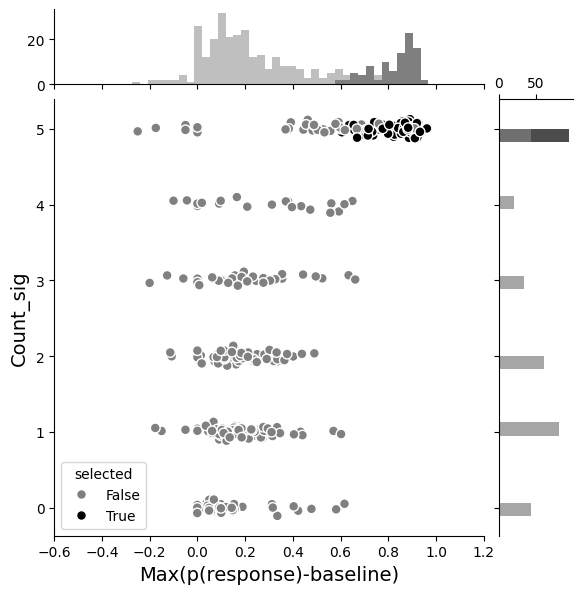

In [127]:

# opto tagged vs not
# Define color palette for groups
palette = {True: "k", False: "gray"}
x_col = 'p_max'
y_col = 'sig_counts'

combined_tagged_units_plot = combined_tagged_units_filtered.copy()
combined_tagged_units_plot[y_col] = combined_tagged_units_plot[y_col]  + np.random.normal(0, 0.05, size=len(combined_tagged_units_plot[y_col]))  # add jitter to y-axis for better visibility

# Create JointGrid
g = sns.JointGrid(data=combined_tagged_units_plot[combined_tagged_units['selected_qc_only']], x=x_col, y=y_col, hue='selected', palette=palette)
g.plot_joint(
    sns.scatterplot,
    edgecolor='white',
    linewidth=1,
    alpha=1,
    s=50   # increase marker size if needed
)

# Add scatter plot in the center

g.ax_joint.set_xlim(-0.6, 1.2)

g.ax_joint.set_xlabel('Max(p(response)-baseline)', fontsize=14)
g.ax_joint.set_ylabel('Count_sig', fontsize=14)

# Add histograms manually for each group
p_max_bins = np.linspace(0, 1, 30)
y_bins = np.linspace(combined_tagged_units_plot[combined_tagged_units['selected_qc_only']][y_col].min(), combined_tagged_units[combined_tagged_units['selected_qc_only']][y_col].max(), 30)
x_bins = np.linspace(-0.6, 1, 50)
for qc_val, color in palette.items():
    subset = combined_tagged_units[combined_tagged_units['selected_qc_only'] & (combined_tagged_units['selected'] == qc_val)]
    # Horizontal histogram for x-axis (default orientation)
    ax = g.ax_marg_x
    ax.hist(subset[x_col], bins=x_bins, color=color, alpha=0.5, edgecolor='none')

    # **VERTICAL histogram for y-axis** using orientation="horizontal"
    ax = g.ax_marg_y
    ax.hist(subset[y_col], bins=y_bins, color=color, alpha=0.7, edgecolor='none',  orientation='horizontal')
g.ax_marg_y.set_axis_on()

g.ax_marg_y.spines["top"].set_visible(True)
g.ax_marg_y.tick_params(
    top=True,
    labeltop=True
)

g.ax_marg_x.set_axis_on()

g.ax_marg_x.spines["left"].set_visible(True)
g.ax_marg_x.tick_params(
    left=True,
    labelleft=True
)


save_panels(g.fig, target_folder, f'opto_pass_{x_col}_{y_col}_{criteria_name}', ['FigureE10e'], exts=('pdf', 'svg'), dpi=300, bbox_inches='tight')
# ---- panel CSV (rule 1 scatter + marginal distributions share these columns) ----
_sub = combined_tagged_units[combined_tagged_units['selected_qc_only']]
save_panel_csv(columns_to_df(**{x_col: _sub[x_col].values, y_col: _sub[y_col].values, 'opto_tagged': _sub['selected'].values}), target_folder, f'opto_pass_{x_col}_{y_col}_{criteria_name}', ['FigureE10e'])
# Show plot
plt.show()

##FigureE10e##



## Go-Cue Excitation vs. Go-Baseline Correlation

Report dataset summary counts, then plot a joint scatter of baseline–response correlation (`bl_response_corr_short`) against normalized response rate for opto-tagged units, with Pearson r annotation.

In [128]:
mask = features_combined['be_filter'].values
aniNames = [parseSessionID(session_curr)[0] for session_curr in features_combined[mask]['session']]
aniNames_F = [parseSessionID(session_curr)[0] for session_curr in features_combined[mask & (features_combined['sex']=='F')]['session']]
print(f"Animals count: {len(set(aniNames))}")
print(f"Animals count (F): {len(set(aniNames_F))}")
print(f"Session count: {len(features_combined[mask]['session'].unique())}")
print(f"Unit count: {len(features_combined[mask])}")

Animals count: 14
Animals count (F): 2
Session count: 22
Unit count: 210


In [129]:
features_combined['response_increase'] = features_combined['response_fr'] - features_combined['bl_mean']
features_combined['response_rate_mean'] = (features_combined['response_fr'] - features_combined['bl_mean'])/features_combined['bl_mean']

['/root/capsule/scratch/result/manuscript/figures/F_basic_ephys/Figure4h_joint_plot_bl_response_corr_response_rate_basic_ephys_all_LC.csv']

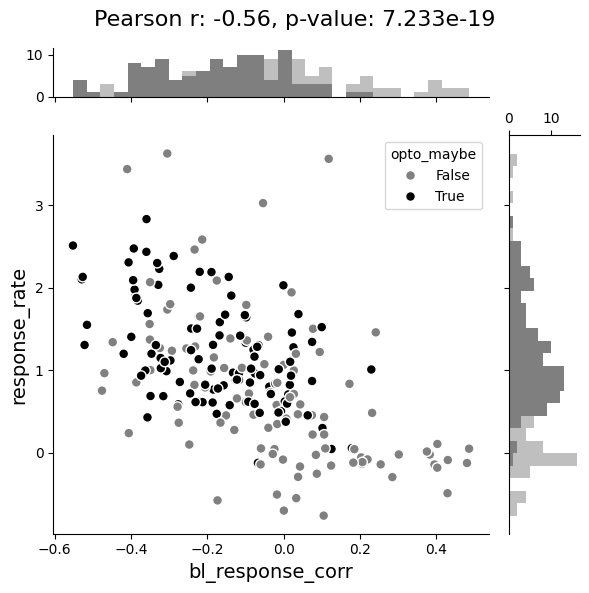

In [130]:
# joint plot between x and y
x_val = 'bl_response_corr'
y_val = 'response_rate'
colorcode = 'opto_maybe'

mask = features_combined['be_filter'].values
palette = {True: 'k', False: 'gray'}

# Create JointGrid with hue so dots are colored by colorcode
g = sns.JointGrid(data=features_combined[mask], x=x_val, y=y_val, hue=colorcode, palette=palette)
g.plot_joint(sns.scatterplot, alpha=1, edgecolor='white', linewidth=1, s=50)
g.ax_joint.set_xlabel(x_val, fontsize=14)
g.ax_joint.set_ylabel(y_val, fontsize=14)

# Add marginal histograms split by colorcode
x_bins = np.linspace(features_combined[mask][x_val].min(), features_combined[mask][x_val].max(), 30)
y_bins = np.linspace(features_combined[mask][y_val].min(), features_combined[mask][y_val].max(), 30)
for val, color in palette.items():
    sub = features_combined[mask][features_combined[mask][colorcode] == val]
    g.ax_marg_x.hist(sub[x_val], bins=x_bins, color=color, alpha=0.5, edgecolor='none')
    g.ax_marg_y.hist(sub[y_val], bins=y_bins, color=color, alpha=0.5, edgecolor='none', orientation='horizontal')

g.ax_marg_y.set_axis_on()
g.ax_marg_y.spines["top"].set_visible(True)
g.ax_marg_y.tick_params(top=True, labeltop=True)
g.ax_marg_x.set_axis_on()
g.ax_marg_x.spines["left"].set_visible(True)
g.ax_marg_x.tick_params(left=True, labelleft=True)

# compute correlation and add to title
corr_coef, p_value = pearsonr(features_combined[mask][x_val], features_combined[mask][y_val])
g.fig.suptitle(f'Pearson r: {corr_coef:.2f}, p-value: {p_value:.3e}', fontsize=16)
plt.tight_layout()
save_panels(g.fig, target_folder, f'joint_plot_{x_val}_{y_val}_{criteria_name}', ['Figure4h'], exts=('svg',), dpi=300, bbox_inches='tight')
# ---- panel CSV (rule 1 scatter) ----
_m = features_combined['be_filter'].values
save_panel_csv(columns_to_df(**{x_val: features_combined[x_val][_m].values, y_val: features_combined[y_val][_m].values, colorcode: features_combined[colorcode][_m].values}), target_folder, f'joint_plot_{x_val}_{y_val}_{criteria_name}', ['Figure4h'])

##Figure4h##

In [131]:
features_combined['pc_1']

0     -0.046538
1     -0.100384
2     -0.048004
3     -0.065050
4     -0.068897
         ...   
292   -0.042443
293         NaN
294         NaN
295         NaN
296   -0.115907
Name: pc_1, Length: 297, dtype: float64

['/root/capsule/scratch/result/manuscript/figures/F_basic_ephys/Figure4h_joint_plot_pc_2_pc_1_basic_ephys_all_LC.csv']

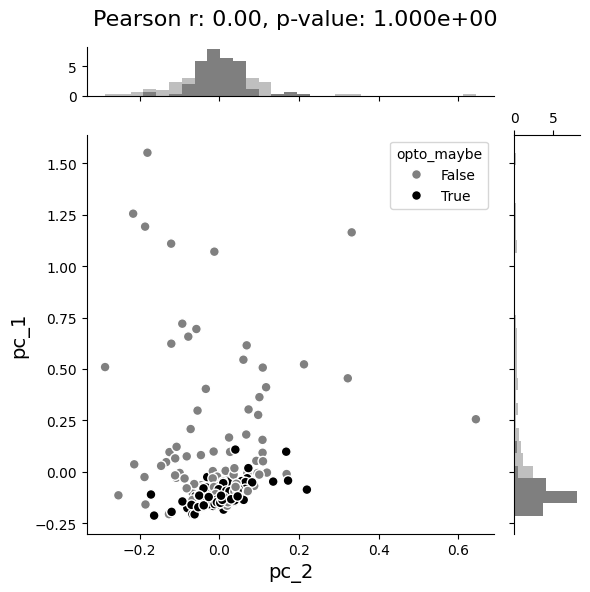

In [133]:
# joint plot between x and y
x_val = 'pc_2'
y_val = 'pc_1'
colorcode = 'opto_maybe'

mask = features_combined['be_filter'].values
palette = {True: 'k', False: 'gray'}

# Create JointGrid with hue so dots are colored by colorcode
g = sns.JointGrid(data=features_combined[mask], x=x_val, y=y_val, hue=colorcode, palette=palette)
g.plot_joint(sns.scatterplot, alpha=1, edgecolor='white', linewidth=1, s=50)
g.ax_joint.set_xlabel(x_val, fontsize=14)
g.ax_joint.set_ylabel(y_val, fontsize=14)

# Add marginal histograms split by colorcode
x_bins = np.linspace(features_combined[mask][x_val].min(), features_combined[mask][x_val].max(), 30)
y_bins = np.linspace(features_combined[mask][y_val].min(), features_combined[mask][y_val].max(), 30)
for val, color in palette.items():
    sub = features_combined[mask][features_combined[mask][colorcode] == val]
    g.ax_marg_x.hist(sub[x_val], bins=x_bins, color=color, alpha=0.5, edgecolor='none', density=True)
    g.ax_marg_y.hist(sub[y_val], bins=y_bins, color=color, alpha=0.5, edgecolor='none', orientation='horizontal', density=True)

g.ax_marg_y.set_axis_on()
g.ax_marg_y.spines["top"].set_visible(True)
g.ax_marg_y.tick_params(top=True, labeltop=True)
g.ax_marg_x.set_axis_on()
g.ax_marg_x.spines["left"].set_visible(True)
g.ax_marg_x.tick_params(left=True, labelleft=True)

# compute correlation and add to title
corr_coef, p_value = pearsonr(features_combined[mask][x_val], features_combined[mask][y_val])
g.fig.suptitle(f'Pearson r: {corr_coef:.2f}, p-value: {p_value:.3e}', fontsize=16)
plt.tight_layout()
save_panels(g.fig, target_folder, f'joint_plot_{x_val}_{y_val}_{criteria_name}', ['Figure4h'], exts=('svg',), dpi=300, bbox_inches='tight')
# ---- panel CSV (rule 1 scatter) ----
_m = features_combined['be_filter'].values
save_panel_csv(columns_to_df(**{x_val: features_combined[x_val][_m].values, y_val: features_combined[y_val][_m].values, colorcode: features_combined[colorcode][_m].values}), target_folder, f'joint_plot_{x_val}_{y_val}_{criteria_name}', ['Figure4h'])

##Figure4h##

In [134]:
features_combined[mask]

,session,unit_id,bl_mean,response_rate,response_fr,response_bias,response_diff,bl_diff,outcome_diff,outcome_diff_abs,...,C1,C2,C3,auto_corr,p_max,sig_counts,selected,opto_maybe,response_increase,response_rate_mean
0,behavior_716325_2024-05-31_10-31-14,14,3.686007,2.462963,12.764505,0.169523,1.027428,-0.057887,0.431376,0.431376,...,"[-0.0034056522243784103, -0.000169557440132295...","[0.03344849647874697, 0.05108980305216013, 0.0...","[-0.00020538881775356227, -0.00132997570975333...","[-0.06853493532619725, 0.032337146780156624, 0...",0.312270,4.0,False,False,9.078498,2.462963
1,behavior_716325_2024-05-31_10-31-14,51,14.120307,-0.019075,13.850967,0.041843,0.058770,-0.077898,-0.248449,0.248449,...,"[-0.008589515414990324, -0.0004276467912129449...","[0.006755654604578594, 0.00893670016484588, 0....","[-2.7908464427331393e-120, -2.0710310824620835...","[-0.17278039359650607, 0.0034852415981613764, ...",0.076357,1.0,False,False,-0.269340,-0.019075
2,behavior_716325_2024-05-31_10-31-14,55,15.171502,-0.024052,14.806598,0.121489,0.044223,-0.064723,-0.225635,0.225635,...,"[-0.004454260878095742, -0.0002217645908660545...","[0.01240209227488113, 0.01792143299673805, 0.0...","[-6.349412396041815e-80, -4.712500793945392e-7...","[-0.09031169750957299, 0.024974107235301614, 0...",0.348995,1.0,False,False,-0.364903,-0.024052
3,behavior_716325_2024-05-31_10-31-14,56,12.420648,-0.122072,10.904437,0.034072,0.009080,-0.082668,-0.316330,0.316330,...,"[-0.00721576023723394, -0.00035925154825728066...","[0.0059343349055975825, 0.010229475560440836, ...","[-1.305588680173825e-75, -9.690011150840231e-7...","[-0.1457288981933331, 0.014467779992532102, 0....",0.206329,1.0,False,False,-1.516212,-0.122072
4,behavior_716325_2024-05-31_10-31-14,64,3.377986,0.434706,4.846416,0.596417,0.085640,-0.035266,-0.230873,0.230873,...,"[-0.05710862168066713, -0.03779433284918335, -...","[0.019983687107993958, 0.030432717230416673, 0...","[-6.0480248427425995e-46, -4.48876841465963e-4...","[-0.08527573135374017, -0.041440161427729966, ...",0.161374,3.0,False,False,1.468430,0.434706
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
287,behavior_784803_2025-07-01_13-58-26,44,94.193989,-0.503988,46.721311,-0.245874,NaN,NaN,-0.254204,0.254204,...,"[0.5489269237980108, 0.4558006538004238, 0.378...","[0.06958076147464141, 0.12910619646375857, 0.1...","[-0.0001894563280299846, -0.001305812341554611...","[0.6624153272296814, 0.6220403220645547, 0.585...",0.000000,5.0,False,False,-47.472678,-0.503988
288,behavior_784803_2025-07-01_13-58-26,48,25.668033,0.278053,32.805100,-0.383730,NaN,NaN,-0.161326,0.161326,...,"[0.06075505411764429, 0.052292359687192494, 0....","[0.046458026646314814, 0.07012093673655036, 0....","[-1.243475939608005e-06, -9.22901362702083e-06...","[0.049057815643138304, 0.1381293885625554, 0.1...",0.185130,3.0,False,False,7.137067,0.278053
290,behavior_784803_2025-07-01_13-58-26,53,32.935792,-0.251732,24.644809,-0.222838,NaN,NaN,0.246443,0.246443,...,"[0.19959166132856676, 0.16738144747638695, 0.1...","[0.02377820753842989, 0.04412015432069365, 0.0...","[-0.00011234732824260284, -0.00076885436966076...","[0.2122778400249007, 0.2572926060536995, 0.223...",0.061508,1.0,False,False,-8.290984,-0.251732
292,behavior_784803_2025-07-01_13-58-26,67,5.322404,0.825804,9.717668,-0.500520,NaN,NaN,0.362467,0.362467,...,"[-0.0014253481152390129, -7.096390406141082e-0...","[0.08579450830858067, 0.06995560641128061, 0.0...","[-0.0001941560816894959, -0.001240294241598664...","[-0.02867629549388507, 0.08531954240706949, 0....",0.717211,5.0,True,True,4.395264,0.825804


['/root/capsule/scratch/result/manuscript/figures/F_basic_ephys/Figure4h_joint_plot_pc_2_pc_1_basic_ephys_all_LC.csv']

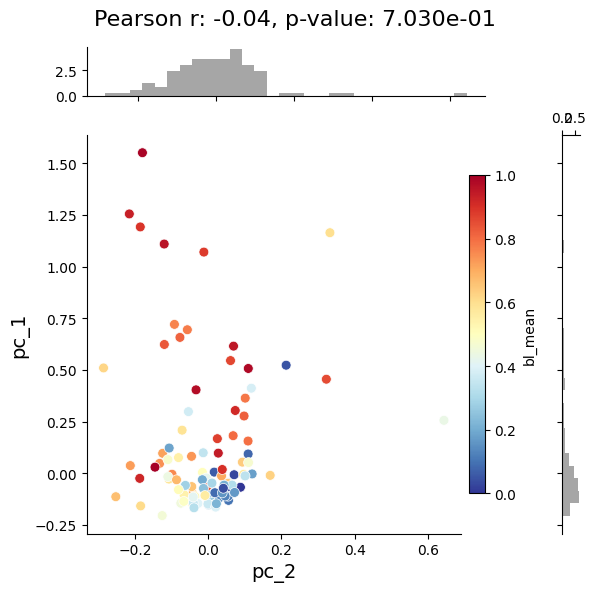

In [136]:
# joint plot between x and y  –  colorcode is a continuous variable, so
# colour the scatter manually instead of using seaborn hue + palette.
x_val = 'pc_2'
y_val = 'pc_1'
colorcode = 'bl_mean'

mask = ~features_combined['opto_maybe'].values
df_plot = features_combined[mask].dropna(subset=[x_val, y_val, colorcode]).copy()

# rank-normalise the continuous colorcode to [0, 1]
from scipy.stats import rankdata as _rankdata
color_vals = df_plot[colorcode].values.astype(float)
color_nl = (_rankdata(color_vals) - 1) / (len(color_vals) - 1)
cmap_cont = plt.cm.RdYlBu_r

# JointGrid without hue (plain axes)
g = sns.JointGrid(data=df_plot, x=x_val, y=y_val)
sc = g.ax_joint.scatter(
    df_plot[x_val], df_plot[y_val],
    c=color_nl, cmap=cmap_cont, vmin=0, vmax=1,
    alpha=1, edgecolor='white', linewidth=0.5, s=50,
)
g.fig.colorbar(sc, ax=g.ax_joint, label=colorcode, fraction=0.04, pad=0.02)
g.ax_joint.set_xlabel(x_val, fontsize=14)
g.ax_joint.set_ylabel(y_val, fontsize=14)

# single marginal histograms (no categorical split for a continuous colorcode)
x_bins = np.linspace(df_plot[x_val].min(), df_plot[x_val].max(), 30)
y_bins = np.linspace(df_plot[y_val].min(), df_plot[y_val].max(), 30)
g.ax_marg_x.hist(df_plot[x_val], bins=x_bins, color='gray', alpha=0.7, edgecolor='none', density=True)
g.ax_marg_y.hist(df_plot[y_val], bins=y_bins, color='gray', alpha=0.7, edgecolor='none',
                 orientation='horizontal', density=True)

g.ax_marg_y.set_axis_on()
g.ax_marg_y.spines["top"].set_visible(True)
g.ax_marg_y.tick_params(top=True, labeltop=True)
g.ax_marg_x.set_axis_on()
g.ax_marg_x.spines["left"].set_visible(True)
g.ax_marg_x.tick_params(left=True, labelleft=True)

# Pearson correlation
corr_coef, p_value = pearsonr(df_plot[x_val], df_plot[y_val])
g.fig.suptitle(f'Pearson r: {corr_coef:.2f}, p-value: {p_value:.3e}', fontsize=16)
plt.tight_layout()
save_panels(g.fig, target_folder, f'joint_plot_{x_val}_{y_val}_{criteria_name}', ['Figure4h'], exts=('svg',), dpi=300, bbox_inches='tight')
# ---- panel CSV (rule 1 scatter) ----
_m = features_combined['be_filter'].values
save_panel_csv(columns_to_df(**{x_val: features_combined[x_val][_m].values, y_val: features_combined[y_val][_m].values, colorcode: features_combined[colorcode][_m].values}), target_folder, f'joint_plot_{x_val}_{y_val}_{criteria_name}', ['Figure4h'])

##Figure4h##

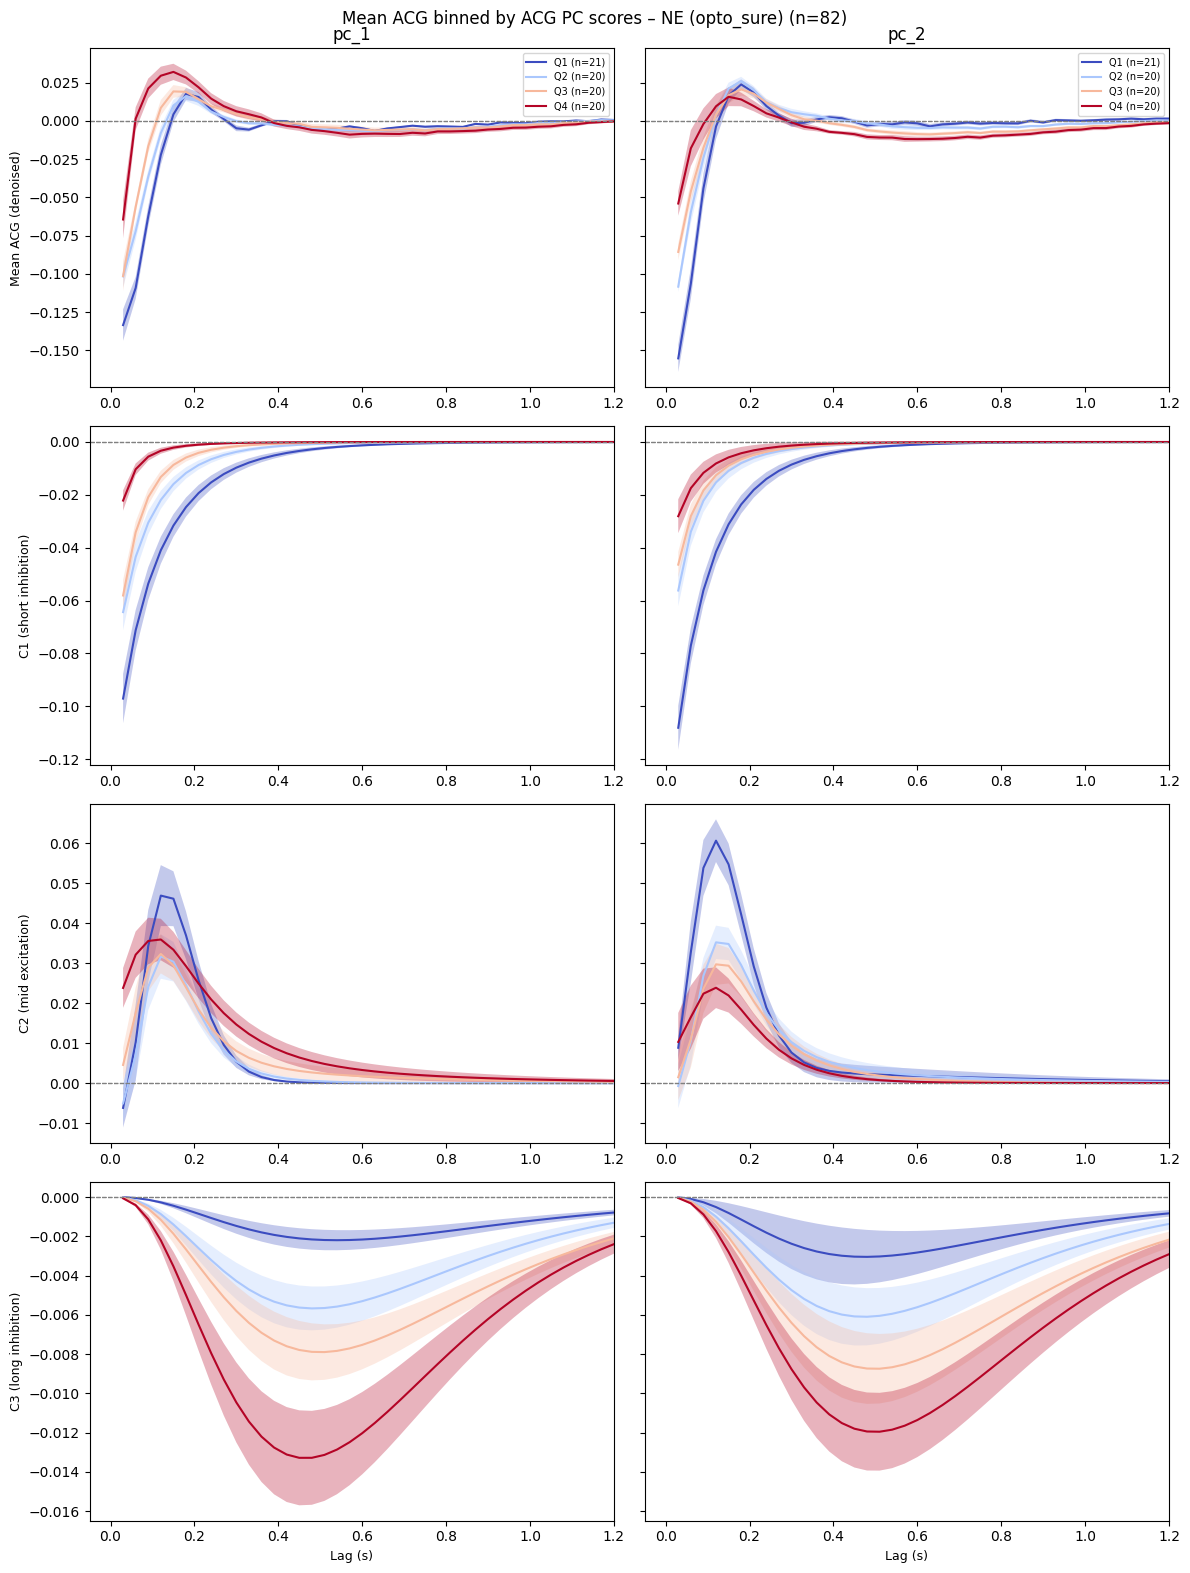

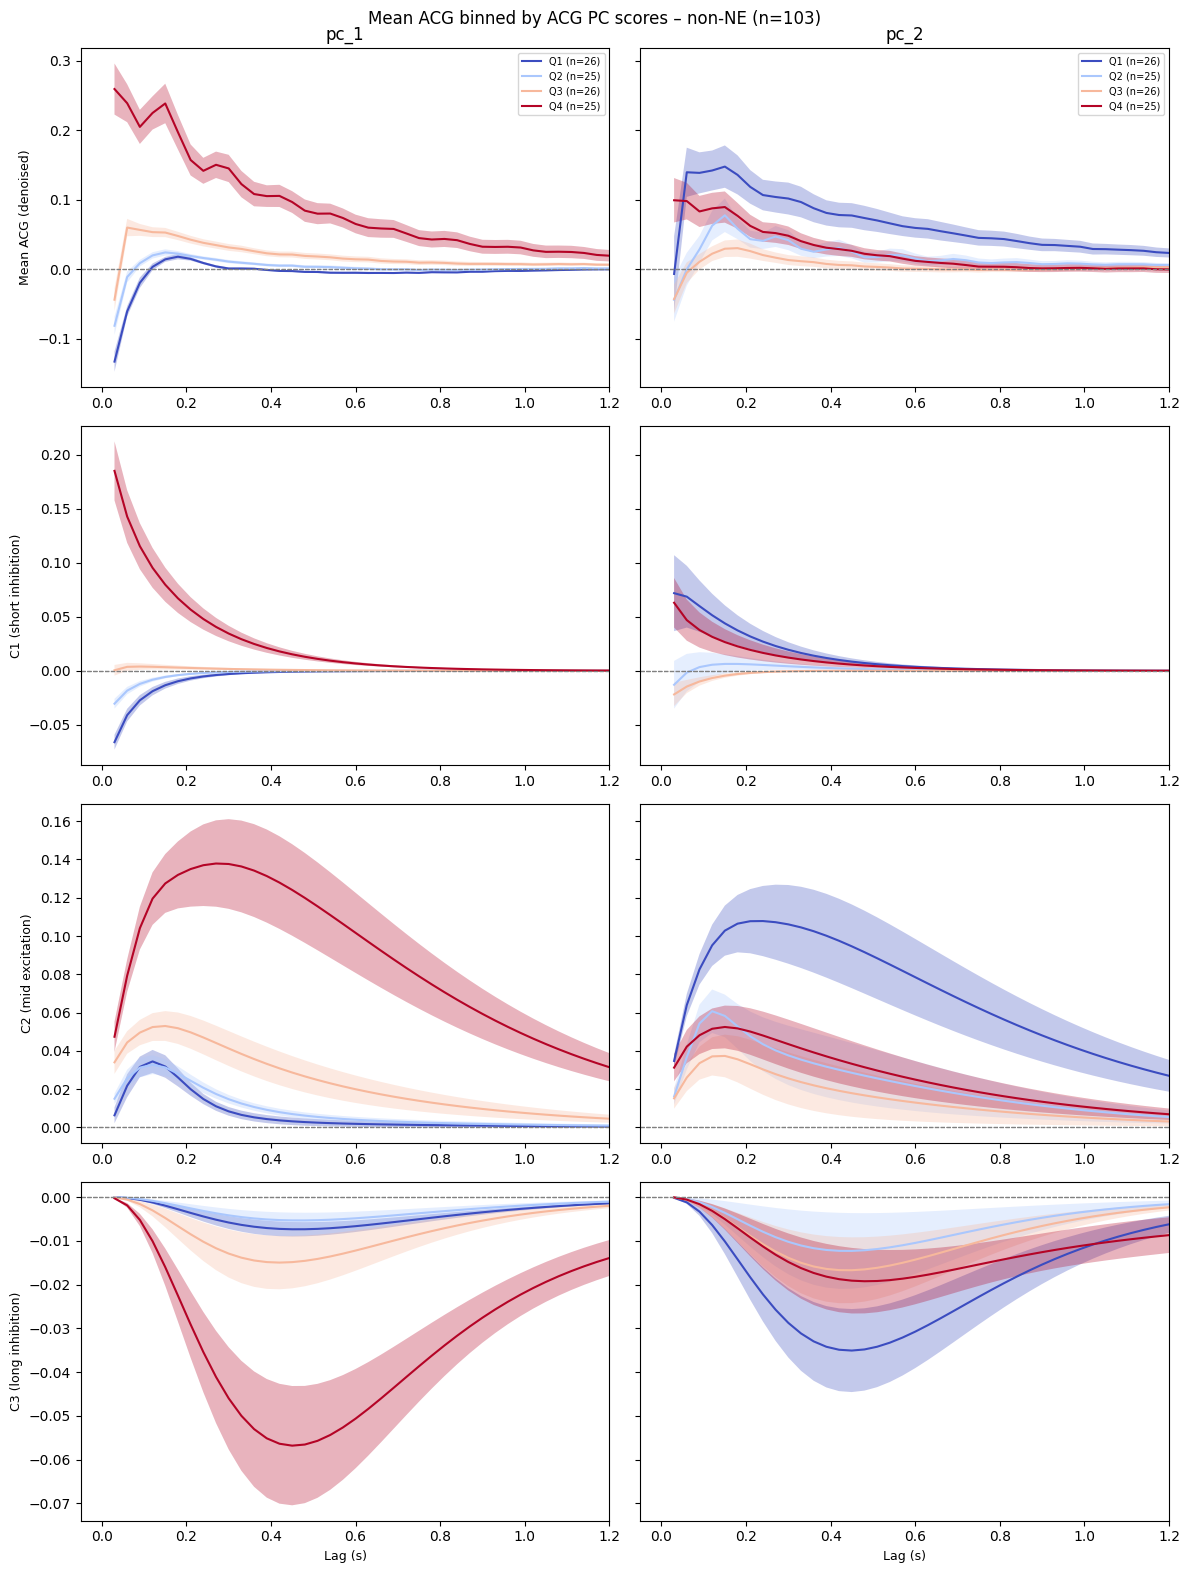

In [138]:
# bin the acg by pc_1 and pc_2, and plot the mean acg for each bin
# separated by NE (opto_maybe=True) vs non-NE (opto_maybe=False) neurons
# mirrors acg_generation.py lines 668-718
import matplotlib.cm as cm

dt = 0.03        # seconds per lag bin (matches acg_generation.py)
bin_num = 4
cmap_bins = cm.get_cmap("coolwarm", bin_num)
pc_cols = ['pc_1', 'pc_2']

# keep units that have ACG data and valid PC scores
mask_acg = (
    features_combined['be_filter'].values &
    features_combined['auto_corr'].notna().values &
    features_combined[pc_cols].notna().all(axis=1).values
)
df_acg = features_combined[mask_acg].reset_index(drop=True)

# rebuild ACG and component matrices from stored list columns
auto_corr_mat = np.array(df_acg['auto_corr'].tolist())   # (n_units, n_lags)
C1_mat_sel    = np.array(df_acg['C1'].tolist())
C2_mat_sel    = np.array(df_acg['C2'].tolist())
C3_mat_sel    = np.array(df_acg['C3'].tolist())

n_lags = auto_corr_mat.shape[1]
x_vals = np.arange(1, n_lags + 1) * dt

row_defs = [
    (auto_corr_mat, 'Mean ACG (denoised)'),
    (C1_mat_sel,    'C1 (short inhibition)'),
    (C2_mat_sel,    'C2 (mid excitation)'),
    (C3_mat_sel,    'C3 (long inhibition)'),
]

groups = {
    'NE (opto_sure)':     df_acg['selected'].values.astype(bool),
    'non-NE':             ~df_acg['opto_maybe'].values.astype(bool),
}

for group_name, group_mask in groups.items():
    n_group = group_mask.sum()
    fig, axes = plt.subplots(
        len(row_defs), len(pc_cols),
        figsize=(6 * len(pc_cols), 4 * len(row_defs)),
        sharey='row',
    )

    for col_i, pc_name in enumerate(pc_cols):
        pc_scores = df_acg[pc_name].values.astype(float)
        valid     = np.isfinite(pc_scores) & group_mask
        curr_quantile = np.quantile(pc_scores[valid], q=np.linspace(0, 1, bin_num + 1))

        for q in range(bin_num):
            bin_mask = valid & (pc_scores >= curr_quantile[q]) & (pc_scores < curr_quantile[q + 1])
            color = cmap_bins(q / (bin_num - 1))

            for row_i, (mat, ylabel) in enumerate(row_defs):
                ax = axes[row_i, col_i]
                mean_trace = np.nanmean(mat[bin_mask], axis=0)
                sem_trace  = np.nanstd(mat[bin_mask], axis=0) / np.sqrt(np.sum(bin_mask))
                ax.plot(x_vals, mean_trace,
                        label=f'Q{q+1} (n={np.sum(bin_mask)})', color=color)
                ax.fill_between(x_vals, mean_trace - sem_trace, mean_trace + sem_trace,
                                alpha=0.3, facecolor=color, edgecolor=None)
                ax.axhline(0, color='gray', lw=0.8, ls='--')
                ax.set_xlim(-0.05, 1.2)
                if col_i == 0:
                    ax.set_ylabel(ylabel, fontsize=9)
                if row_i == 0:
                    ax.set_title(pc_name)
                    ax.legend(loc='upper right', fontsize=7)
                if row_i == len(row_defs) - 1:
                    ax.set_xlabel('Lag (s)', fontsize=9)

    plt.suptitle(f'Mean ACG binned by ACG PC scores – {group_name} (n={n_group})', fontsize=12)
    plt.tight_layout()
    group_tag = 'NE' if 'NE (' in group_name else 'nonNE'
    save_panels(fig, target_folder, f'acg_binned_by_pc_{group_tag}_{criteria_name}', [],
                exts=('pdf', 'svg'), dpi=150, bbox_inches='tight')
    plt.show()

In [140]:
combined_tagged_units_filtered[~combined_tagged_units_filtered['opto_maybe']].groupby('decoder').count()

,session,unit_id,qc_pass,opto_tagged,in_df,trial_count,p_max,p_mean,sig_counts,lat_max_p,...,y_ccf,z_ccf,sd,rec_len,selected_qc_only,count_max,selected_opto_only,selected,selected_no_opto,opto_maybe
decoder,,,,,,,,,,,,,,,,,,,,,
mua,67,67,67,67,67,67,67,67,67,62,...,64,64,67,67,67,0,67,67,67,67
sua,183,183,183,183,183,183,183,183,183,183,...,158,158,183,183,183,0,183,183,183,183
